# Setup configuration

In [1]:
import os
from pathlib import Path

In [2]:
PROJECT_DIR = Path(
    "/rs1/researchers/a/amallav/species_classification/ecological_informatics"
)
INPUT_FILE = (
    PROJECT_DIR
    / "notebooks/object_detection/output/analysis/bioclip2_input_detections.parquet"
)
OUTPUT_DIR = (
    PROJECT_DIR / "notebooks/species_identification/output_manual/bioclip_full_run"
)
HF_HOME = PROJECT_DIR / "models/hf_home"

In [3]:
TOP_K = 5
SAVE_EVERY = 25  # Number of attempted CROPS per checkpoint
MAX_CROPS = 10  # For full dataset: None AND need to change OUTPUT_DIR
MODEL_NAME = "hf-hub:imageomics/bioclip-2"

In [4]:
os.environ["HF_HOME"] = str(HF_HOME)
os.environ["HF_HUB_CACHE"] = str(HF_HOME / "hub")
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

In [5]:
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

/usr/local/usrapps/ftrscape/snair3/env_AiPipeline/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
print("Input:", INPUT_FILE)
print("Output:", OUTPUT_DIR)
print("Model cache:", os.environ["HF_HOME"])
print("GPU available:", torch.cuda.is_available())

Input: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/object_detection/output/analysis/bioclip2_input_detections.parquet
Output: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/species_identification/output_manual/bioclip_notebook_test
Model cache: /rs1/researchers/a/amallav/species_classification/ecological_informatics/models/hf_home
GPU available: True


# Load and validate the input crops


In [7]:
df = pd.read_parquet(INPUT_FILE)

In [8]:
df.columns

Index(['obs_id', 'photo_id', 'photo_license_code', 'photo_url', 'obs_url',
       'quality_grade', 'obs_license_code', 'predator_prey_role',
       'scientific_name', 'taxon_rank', 'common_name', 'latitude', 'longitude',
       'positional_accuracy', 'photo_count', 'kingdom_name', 'phylum_name',
       'class_name', 'order_name', 'family_name', 'genus_name', 'species_name',
       'subspecies_name', 'subfamily_name', 'hybrid_name', 'complex_name',
       'form_name', 'subgenus_name', 'variety_name', 'tribe_name', 'country',
       'state', 'city', 'file_name', 'image_byte_size', 'image_local_path',
       'image_download_url', 'grounding_dino_prompt', 'source_row',
       'img_width', 'img_height', 'n_detections', 'max_score', 'mean_score',
       'detection_flag', 'prompt_used', 'rank', 'score', 'group', 'label',
       'x0', 'y0', 'x1', 'y1', 'box_area_frac', 'aspect_ratio',
       'edge_proximity_frac', 'center_offset_frac', 'is_valid_box',
       'score_rank_gap', 'crop_x0', 'crop_

In [9]:
valid = (
    (df["crop_x0"] >= 0)
    & (df["crop_y0"] >= 0)
    & (df["crop_x1"] <= df["img_width"])
    & (df["crop_y1"] <= df["img_height"])
    & (df["crop_x1"] > df["crop_x0"])
    & (df["crop_y1"] > df["crop_y0"])
)

assert valid.all(), "Some crop coordinates are invalid."

In [10]:
columns_to_remove = ["x0", "y0", "x1", "y1", "is_valid_box", "crop_valid"]

df_clean = df.drop(columns=columns_to_remove).copy()

In [11]:
# correct the edge proximity based on the crop coordinates
# Image diagonal (used to normalize distances)
image_diagonal = np.hypot(df_clean["img_width"], df_clean["img_height"])

# Distance from each crop boundary to its corresponding image edge
left = df_clean["crop_x0"]
top = df_clean["crop_y0"]
right = df_clean["img_width"] - df_clean["crop_x1"]
bottom = df_clean["img_height"] - df_clean["crop_y1"]

# The nearest edge determines the proximity.
nearest_edge = pd.concat([left, top, right, bottom], axis=1).min(axis=1)

# Normalize by image diagonal to compare images of different sizes.
df_clean["edge_proximity_frac"] = nearest_edge / image_diagonal

print(df_clean["edge_proximity_frac"].describe())


count    29391.000000
mean         0.092994
std          0.075064
min          0.000000
25%          0.023812
50%          0.082108
75%          0.151562
max          0.317764
Name: edge_proximity_frac, dtype: float64


In [12]:
print("Total crops:", len(df_clean))
print("Unique input images:", df_clean["source_row"].nunique())

display(df_clean.head())

Total crops: 29391
Unique input images: 22524


,obs_id,photo_id,photo_license_code,photo_url,obs_url,quality_grade,obs_license_code,predator_prey_role,scientific_name,taxon_rank,...,box_area_frac,aspect_ratio,edge_proximity_frac,center_offset_frac,score_rank_gap,crop_x0,crop_y0,crop_x1,crop_y1,was_out_of_bounds
0,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
1,338604,421441,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,0.241431,1.9402,0.058736,0.1131,NaN,332,307,948,626,False
2,338604,421442,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,0.129188,0.9217,0.127518,0.1472,0.4518,536,288,848,626,False
3,338604,421442,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,0.011971,1.3013,0.229533,0.0768,0.4518,538,297,652,384,False
4,338604,421443,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,0.157576,2.5453,0.051007,0.1606,0.4941,387,415,958,640,False


## check missing columns

In [13]:
required_columns = [
    "source_row",
    "photo_id",
    "rank",
    "image_local_path",
    "crop_x0",
    "crop_y0",
    "crop_x1",
    "crop_y1",
    "img_width",
    "img_height",
]

missing = set(required_columns) - set(df_clean.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")


In [14]:
assert not df_clean.duplicated(subset=["source_row", "rank"]).any()

print("Required columns and crop IDs verified.")

Required columns and crop IDs verified.


In [15]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Crops selected:", len(df))
print("Unique images:", df["source_row"].nunique())
display(
    df[
        [
            "source_row",
            "photo_id",
            "rank",
            "species_name",
            "crop_x0",
            "crop_y0",
            "crop_x1",
            "crop_y1",
        ]
    ].head()
)

Crops selected: 29391
Unique images: 22524


,source_row,photo_id,rank,species_name,crop_x0,crop_y0,crop_x1,crop_y1
0,0,421440,1,Geococcyx californianus,346,387,920,619
1,1,421441,1,Geococcyx californianus,332,307,948,626
2,2,421442,1,Geococcyx californianus,536,288,848,626
3,2,421442,2,Geococcyx californianus,538,297,652,384
4,3,421443,1,Geococcyx californianus,387,415,958,640


# Loading BioCLIP2

In [16]:
import torch
from bioclip import TreeOfLifeClassifier, Rank

In [17]:
if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU detected; use a GPU-enabled notebook session")

In [18]:
import os
from pathlib import Path

HF_HOME = PROJECT_DIR / "models/hf_home"

os.environ["HF_HOME"] = str(HF_HOME)
os.environ["HF_HUB_CACHE"] = str(HF_HOME / "hub")
os.environ["HF_HUB_OFFLINE"] = "1"

In [19]:
print("HF_HOME:", os.environ.get("HF_HOME"))
print("HF_HUB_CACHE:", os.environ.get("HF_HUB_CACHE"))
print("Offline mode:", os.environ.get("HF_HUB_OFFLINE"))

HF_HOME: /rs1/researchers/a/amallav/species_classification/ecological_informatics/models/hf_home
HF_HUB_CACHE: /rs1/researchers/a/amallav/species_classification/ecological_informatics/models/hf_home/hub
Offline mode: 1


In [20]:
DEVICE = "cuda"
classifier = TreeOfLifeClassifier(device=DEVICE, model_str=MODEL_NAME)
print("Loaded:", MODEL_NAME, "on", DEVICE)

Loaded: hf-hub:imageomics/bioclip-2 on cuda


# Classifying one Grounding DINO crop with BioCLIP2

In [23]:
row = df_clean.iloc[0]

print("Photo ID:", row["photo_id"])
print("Grounding DINO rank:", row["rank"])
print("Grounding DINO score:", row["score"])
print("Grounding DINO label:", row["label"])

Photo ID: 421440
Grounding DINO rank: 1
Grounding DINO score: 0.8916065692901611
Grounding DINO label: brown bird


In [24]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(row["image_local_path"]).convert("RGB")

coords = (
    int(row["crop_x0"]),
    int(row["crop_y0"]),
    int(row["crop_x1"]),
    int(row["crop_y1"]),
)

crop = image.crop(coords)

print("Original image size:", image.size)
print("Crop size:", crop.size)

Original image size: (1024, 790)
Crop size: (574, 232)


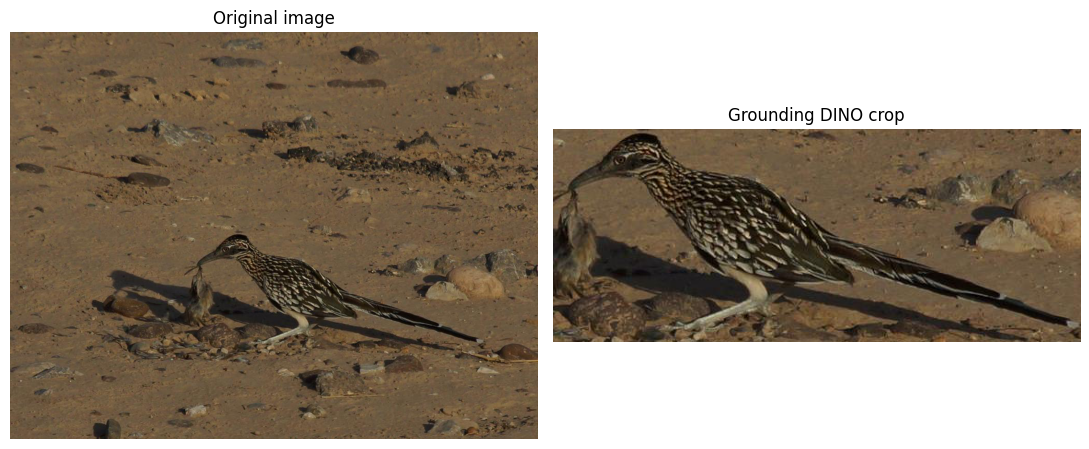

In [25]:
# Visualize the original image and crop
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(crop)
axes[1].set_title("Grounding DINO crop")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [26]:
assert image.size == (int(row["img_width"]), int(row["img_height"])), (
    "Image dimensions changed since detection."
)

assert crop.width > 0 and crop.height > 0

In [30]:
# Run BioCLIP2 identification
predictions = classifier.predict([crop], rank=Rank.SPECIES, k=TOP_K)

predictions


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.68s/images]


[{'file_name': '0',
  'kingdom': 'Animalia',
  'phylum': 'Chordata',
  'class': 'Aves',
  'order': 'Cuculiformes',
  'family': 'Cuculidae',
  'genus': 'Geococcyx',
  'species_epithet': 'californianus',
  'species': 'Geococcyx californianus',
  'common_name': 'Greater Roadrunner',
  'score': 0.9685913324356079},
 {'file_name': '0',
  'kingdom': 'Animalia',
  'phylum': 'Chordata',
  'class': 'Aves',
  'order': 'Cuculiformes',
  'family': 'Cuculidae',
  'genus': 'Geococcyx',
  'species_epithet': 'velox',
  'species': 'Geococcyx velox',
  'common_name': 'Lesser roadrunner',
  'score': 0.021865520626306534},
 {'file_name': '0',
  'kingdom': 'Animalia',
  'phylum': 'Chordata',
  'class': 'Aves',
  'order': 'Passeriformes',
  'family': 'Troglodytidae',
  'genus': 'Campylorhynchus',
  'species_epithet': 'brunneicapillus',
  'species': 'Campylorhynchus brunneicapillus',
  'common_name': 'Cactus Wren',
  'score': 0.00024471760843880475},
 {'file_name': '0',
  'kingdom': 'Animalia',
  'phylum': '

In [31]:
# Inspect the actual prediction format
print("Prediction type:", type(predictions))
print("Number of predictions:", len(predictions))

if len(predictions) > 0:
    print("\nFirst prediction:")
    print(predictions[0])

Prediction type: <class 'list'>
Number of predictions: 5

First prediction:
{'file_name': '0', 'kingdom': 'Animalia', 'phylum': 'Chordata', 'class': 'Aves', 'order': 'Cuculiformes', 'family': 'Cuculidae', 'genus': 'Geococcyx', 'species_epithet': 'californianus', 'species': 'Geococcyx californianus', 'common_name': 'Greater Roadrunner', 'score': 0.9685913324356079}


In [37]:
print("Reference species:", row["species_name"])
print("Reference genus:", row["genus_name"])
print("Reference family:", row["family_name"])
if predictions[0]['species'] == row["species_name"]: print("Model's output matches with the ground label")

Reference species: Geococcyx californianus
Reference genus: Geococcyx
Reference family: Cuculidae
Model's output matches with the ground label


In [38]:
print(type(predictions))
print("Number of results:", len(predictions))

print("\nFirst result:")
print(predictions[0])

<class 'list'>
Number of results: 5

First result:
{'file_name': '0', 'kingdom': 'Animalia', 'phylum': 'Chordata', 'class': 'Aves', 'order': 'Cuculiformes', 'family': 'Cuculidae', 'genus': 'Geococcyx', 'species_epithet': 'californianus', 'species': 'Geococcyx californianus', 'common_name': 'Greater Roadrunner', 'score': 0.9685913324356079}


In [39]:
if isinstance(predictions[0], dict):
    print(predictions[0].keys())

dict_keys(['file_name', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species_epithet', 'species', 'common_name', 'score'])


In [40]:
row = df_clean.iloc[0]
crop_info = row.to_dict()

print(crop_info["photo_id"])
print(crop_info["rank"])
print(crop_info["score"])
print(crop_info["crop_x0"])


421440
1
0.8916065692901611
346


In [41]:
from pprint import pprint

pprint(predictions[0])

{'class': 'Aves',
 'common_name': 'Greater Roadrunner',
 'family': 'Cuculidae',
 'file_name': '0',
 'genus': 'Geococcyx',
 'kingdom': 'Animalia',
 'order': 'Cuculiformes',
 'phylum': 'Chordata',
 'score': 0.9685913324356079,
 'species': 'Geococcyx californianus',
 'species_epithet': 'californianus'}


In [42]:
print("Number of candidates:", len(predictions))

for i, prediction in enumerate(predictions, start=1):
    print(i, prediction["species"], prediction["score"])

Number of candidates: 5
1 Geococcyx californianus 0.9685913324356079
2 Geococcyx velox 0.021865520626306534
3 Campylorhynchus brunneicapillus 0.00024471760843880475
4 Schistocerca gregaria 0.00014097621897235513
5 Aspidoscelis tigris 0.00011531630298122764


In [43]:
candidate_df = pd.DataFrame(predictions)

candidate_df["model_prediction_rank"] = range(1, len(candidate_df) + 1)

display(candidate_df)

,file_name,kingdom,phylum,class,order,family,genus,species_epithet,species,common_name,score,model_prediction_rank
0,0,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,californianus,Geococcyx californianus,Greater Roadrunner,0.968591,1
1,0,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,velox,Geococcyx velox,Lesser roadrunner,0.021866,2
2,0,Animalia,Chordata,Aves,Passeriformes,Troglodytidae,Campylorhynchus,brunneicapillus,Campylorhynchus brunneicapillus,Cactus Wren,0.000245,3
3,0,Animalia,Arthropoda,Insecta,Orthoptera,Acrididae,Schistocerca,gregaria,Schistocerca gregaria,Desert locust,0.000141,4
4,0,Animalia,Chordata,Squamata,,Teiidae,Aspidoscelis,tigris,Aspidoscelis tigris,Tiger whiptail,0.000115,5


In [44]:
candidate_df = candidate_df.rename(columns={
    "kingdom": "model_kingdom_name",
    "phylum": "model_phylum_name",
    "class": "model_class_name",
    "order": "model_order_name",
    "family": "model_family_name",
    "genus": "model_genus_name",
    "species": "model_species_name",
    "species_epithet": "model_species_epithet",
    "common_name": "model_common_name",
    "score": "model_score"
})

candidate_df = candidate_df.drop(columns=["file_name"])

display(candidate_df)

,model_kingdom_name,model_phylum_name,model_class_name,model_order_name,model_family_name,model_genus_name,model_species_epithet,model_species_name,model_common_name,model_score,model_prediction_rank
0,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,californianus,Geococcyx californianus,Greater Roadrunner,0.968591,1
1,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,velox,Geococcyx velox,Lesser roadrunner,0.021866,2
2,Animalia,Chordata,Aves,Passeriformes,Troglodytidae,Campylorhynchus,brunneicapillus,Campylorhynchus brunneicapillus,Cactus Wren,0.000245,3
3,Animalia,Arthropoda,Insecta,Orthoptera,Acrididae,Schistocerca,gregaria,Schistocerca gregaria,Desert locust,0.000141,4
4,Animalia,Chordata,Squamata,,Teiidae,Aspidoscelis,tigris,Aspidoscelis tigris,Tiger whiptail,0.000115,5


In [45]:
crop_info = row.to_dict()

results = []

for _, candidate in candidate_df.iterrows():
    result = {
        **crop_info,
        **candidate.to_dict()
    }
    results.append(result)

result_df = pd.DataFrame(results)

display(result_df)

,obs_id,photo_id,photo_license_code,photo_url,obs_url,quality_grade,obs_license_code,predator_prey_role,scientific_name,taxon_rank,...,model_phylum_name,model_class_name,model_order_name,model_family_name,model_genus_name,model_species_epithet,model_species_name,model_common_name,model_score,model_prediction_rank
0,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,californianus,Geococcyx californianus,Greater Roadrunner,0.968591,1
1,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,velox,Geococcyx velox,Lesser roadrunner,0.021866,2
2,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,Chordata,Aves,Passeriformes,Troglodytidae,Campylorhynchus,brunneicapillus,Campylorhynchus brunneicapillus,Cactus Wren,0.000245,3
3,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,Arthropoda,Insecta,Orthoptera,Acrididae,Schistocerca,gregaria,Schistocerca gregaria,Desert locust,0.000141,4
4,338604,421440,cc-by-nc,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,research,cc-by-nc,predator,Geococcyx californianus,species,...,Chordata,Squamata,,Teiidae,Aspidoscelis,tigris,Aspidoscelis tigris,Tiger whiptail,0.000115,5


In [46]:
columns_to_view = [
    "photo_id",
    "source_row",
    "rank",
    "score",
    "label",
    "species_name",
    "model_prediction_rank",
    "model_species_name",
    "model_score"
]

display(result_df[columns_to_view])

,photo_id,source_row,rank,score,label,species_name,model_prediction_rank,model_species_name,model_score
0,421440,0,1,0.891607,brown bird,Geococcyx californianus,1,Geococcyx californianus,0.968591
1,421440,0,1,0.891607,brown bird,Geococcyx californianus,2,Geococcyx velox,0.021866
2,421440,0,1,0.891607,brown bird,Geococcyx californianus,3,Campylorhynchus brunneicapillus,0.000245
3,421440,0,1,0.891607,brown bird,Geococcyx californianus,4,Schistocerca gregaria,0.000141
4,421440,0,1,0.891607,brown bird,Geococcyx californianus,5,Aspidoscelis tigris,0.000115


# function to classify one crop

In [47]:
from PIL import Image
import pandas as pd

def classify_crop(row):
    # Open the image and extract its Grounding DINO crop
    with Image.open(row["image_local_path"]) as image:
        image = image.convert("RGB")

        coords = (
            int(row["crop_x0"]),
            int(row["crop_y0"]),
            int(row["crop_x1"]),
            int(row["crop_y1"])
        )

        crop = image.crop(coords)

    # Obtain the Top-5 BioCLIP2 candidates
    predictions = classifier.predict(
        [crop],
        rank=Rank.SPECIES,
        k=TOP_K
    )

    # Convert predictions to a DataFrame
    result = pd.DataFrame(predictions)

    result["model_prediction_rank"] = range(1, len(result) + 1)

    # Rename prediction columns
    result = result.rename(columns={
        "kingdom": "model_kingdom_name",
        "phylum": "model_phylum_name",
        "class": "model_class_name",
        "order": "model_order_name",
        "family": "model_family_name",
        "genus": "model_genus_name",
        "species": "model_species_name",
        "species_epithet": "model_species_epithet",
        "common_name": "model_common_name",
        "score": "model_score"
    })

    result = result.drop(columns=["file_name"], errors="ignore")

    # Attach original input metadata to each candidate
    for column, value in row.items():
        result[column] = value

    return result

In [48]:
test_result = classify_crop(df_clean.iloc[0])

display(test_result[[
    "photo_id",
    "rank",
    "score",
    "model_prediction_rank",
    "model_species_name",
    "model_score"
]])

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 58.02images/s]


,photo_id,rank,score,model_prediction_rank,model_species_name,model_score
0,421440,1,0.891607,1,Geococcyx californianus,0.968591
1,421440,1,0.891607,2,Geococcyx velox,0.021866
2,421440,1,0.891607,3,Campylorhynchus brunneicapillus,0.000245
3,421440,1,0.891607,4,Schistocerca gregaria,0.000141
4,421440,1,0.891607,5,Aspidoscelis tigris,0.000115


# Test on 10 crops

In [50]:
test_rows = df_clean.head(10)

results = []

for _, row in test_rows.iterrows():
    result = classify_crop(row)
    results.append(result)

test_predictions = pd.concat(results, ignore_index=True)

print("Crops processed:", len(test_rows))
print("Candidate predictions:", len(test_predictions))

display(test_predictions.head())

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 57.30images/s]

Crops processed: 10
Candidate predictions: 50


,model_kingdom_name,model_phylum_name,model_class_name,model_order_name,model_family_name,model_genus_name,model_species_epithet,model_species_name,model_common_name,model_score,...,box_area_frac,aspect_ratio,edge_proximity_frac,center_offset_frac,score_rank_gap,crop_x0,crop_y0,crop_x1,crop_y1,was_out_of_bounds
0,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,californianus,Geococcyx californianus,Greater Roadrunner,0.968591,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
1,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,velox,Geococcyx velox,Lesser roadrunner,0.021866,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
2,Animalia,Chordata,Aves,Passeriformes,Troglodytidae,Campylorhynchus,brunneicapillus,Campylorhynchus brunneicapillus,Cactus Wren,0.000245,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
3,Animalia,Arthropoda,Insecta,Orthoptera,Acrididae,Schistocerca,gregaria,Schistocerca gregaria,Desert locust,0.000141,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
4,Animalia,Chordata,Squamata,,Teiidae,Aspidoscelis,tigris,Aspidoscelis tigris,Tiger whiptail,0.000115,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False


In [51]:
from tqdm.auto import tqdm

# 10 crops for testing. None to process the entire dataset.
MAX_CROPS = None

if MAX_CROPS is None:
    work_df = df_clean
else:
    work_df = df_clean.head(MAX_CROPS)

results = []

for _, row in tqdm(work_df.iterrows(), total=len(work_df)):
    prediction_df = classify_crop(row)
    results.append(prediction_df)

print("Finished processing", len(results), "crops.")

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 62.81images/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 70.59images/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 72.53images/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 77.58images/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 59.71images/s]

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 15.51it/s]

Finished processing 10 crops.


In [54]:
all_predictions = pd.concat(
    results,
    ignore_index=True
)

print("Total crops:", len(results))
print("Total species candidates:", len(all_predictions))

display(all_predictions.head())

Total crops: 10
Total species candidates: 50


,model_kingdom_name,model_phylum_name,model_class_name,model_order_name,model_family_name,model_genus_name,model_species_epithet,model_species_name,model_common_name,model_score,...,box_area_frac,aspect_ratio,edge_proximity_frac,center_offset_frac,score_rank_gap,crop_x0,crop_y0,crop_x1,crop_y1,was_out_of_bounds
0,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,californianus,Geococcyx californianus,Greater Roadrunner,0.968591,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
1,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,velox,Geococcyx velox,Lesser roadrunner,0.021866,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
2,Animalia,Chordata,Aves,Passeriformes,Troglodytidae,Campylorhynchus,brunneicapillus,Campylorhynchus brunneicapillus,Cactus Wren,0.000245,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
3,Animalia,Arthropoda,Insecta,Orthoptera,Acrididae,Schistocerca,gregaria,Schistocerca gregaria,Desert locust,0.000141,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False
4,Animalia,Chordata,Squamata,,Teiidae,Aspidoscelis,tigris,Aspidoscelis tigris,Tiger whiptail,0.000115,...,0.163672,2.4779,0.080413,0.1253,NaN,346,387,920,619,False


# Save one Parquet file

In [55]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "bioclip2_all_candidate.parquet"

all_predictions.to_parquet(
    output_file,
    index=False
)

print("Saved to:", output_file)

Saved to: /rs1/researchers/a/amallav/species_classification/ecological_informatics/notebooks/species_identification/output_manual/bioclip_notebook_test/bioclip2_all_candidates.parquet
